# DSAN 6600 - 00_results_demo.ipynb

**Demo: every headline number in the project, rebuilt from the saved predictions.**

Runs in under a minute on a laptop: no PTB-XL download, no GPU. It reads every `*_preds.csv` in `cnn_results/`, `results/` and `hubert_results/`, checks that all models were scored on the same 3,979 test ECGs with the same labels, and recomputes the tables in the final report.

To see training run end to end instead, use `python src/quick_demo.py` (small CNN on ~1,000 ECGs, CPU, a few minutes) or the full notebooks 01-06.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath("../src"))
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
import evaluate as ev

files = ev.find_prediction_files()
preds = ev.load_predictions(files)
n_test = ev.check_same_test_set(preds)
print(f"{len(files)} prediction files | {preds['model'].nunique()} models | all scored on the same {n_test} test ECGs")

21 prediction files | 9 models | all scored on the same 3979 test ECGs


## 1. Macro AUROC by test sex (mean and std over seeds)

Gap = male AUROC − female AUROC; positive means the model does worse for women.

In [2]:
summary, runs = ev.summary_table(preds)
cols = ["n_seeds", "auroc_all_mean", "auroc_all_std", "auroc_male_mean", "auroc_female_mean",
        "gap_m_minus_f_mean", "gap_m_minus_f_std", "auprc_female_mean"]
summary[cols].sort_values("auroc_all_mean", ascending=False).round(3)

,n_seeds,auroc_all_mean,auroc_all_std,auroc_male_mean,auroc_female_mean,gap_m_minus_f_mean,gap_m_minus_f_std,auprc_female_mean
model,,,,,,,,
cnn_all,3,0.924,0.003,0.930,0.917,0.012,0.001,0.801
cnn_male,3,0.916,0.001,0.924,0.907,0.017,0.001,0.778
cnn_female,3,0.910,0.001,0.913,0.905,0.008,0.002,0.779
improved_logreg_all,3,0.765,0.000,0.768,0.763,0.005,0.000,0.543
improved_logreg_female,3,0.764,0.000,0.762,0.769,-0.007,0.000,0.544
improved_logreg_male,3,0.756,0.000,0.765,0.747,0.018,0.000,0.521
logreg_all,1,0.573,0.000,0.574,0.572,0.002,0.000,0.322
logreg_male,1,0.552,0.000,0.552,0.552,0.000,0.000,0.305
logreg_female,1,0.533,0.000,0.535,0.530,0.004,0.000,0.293


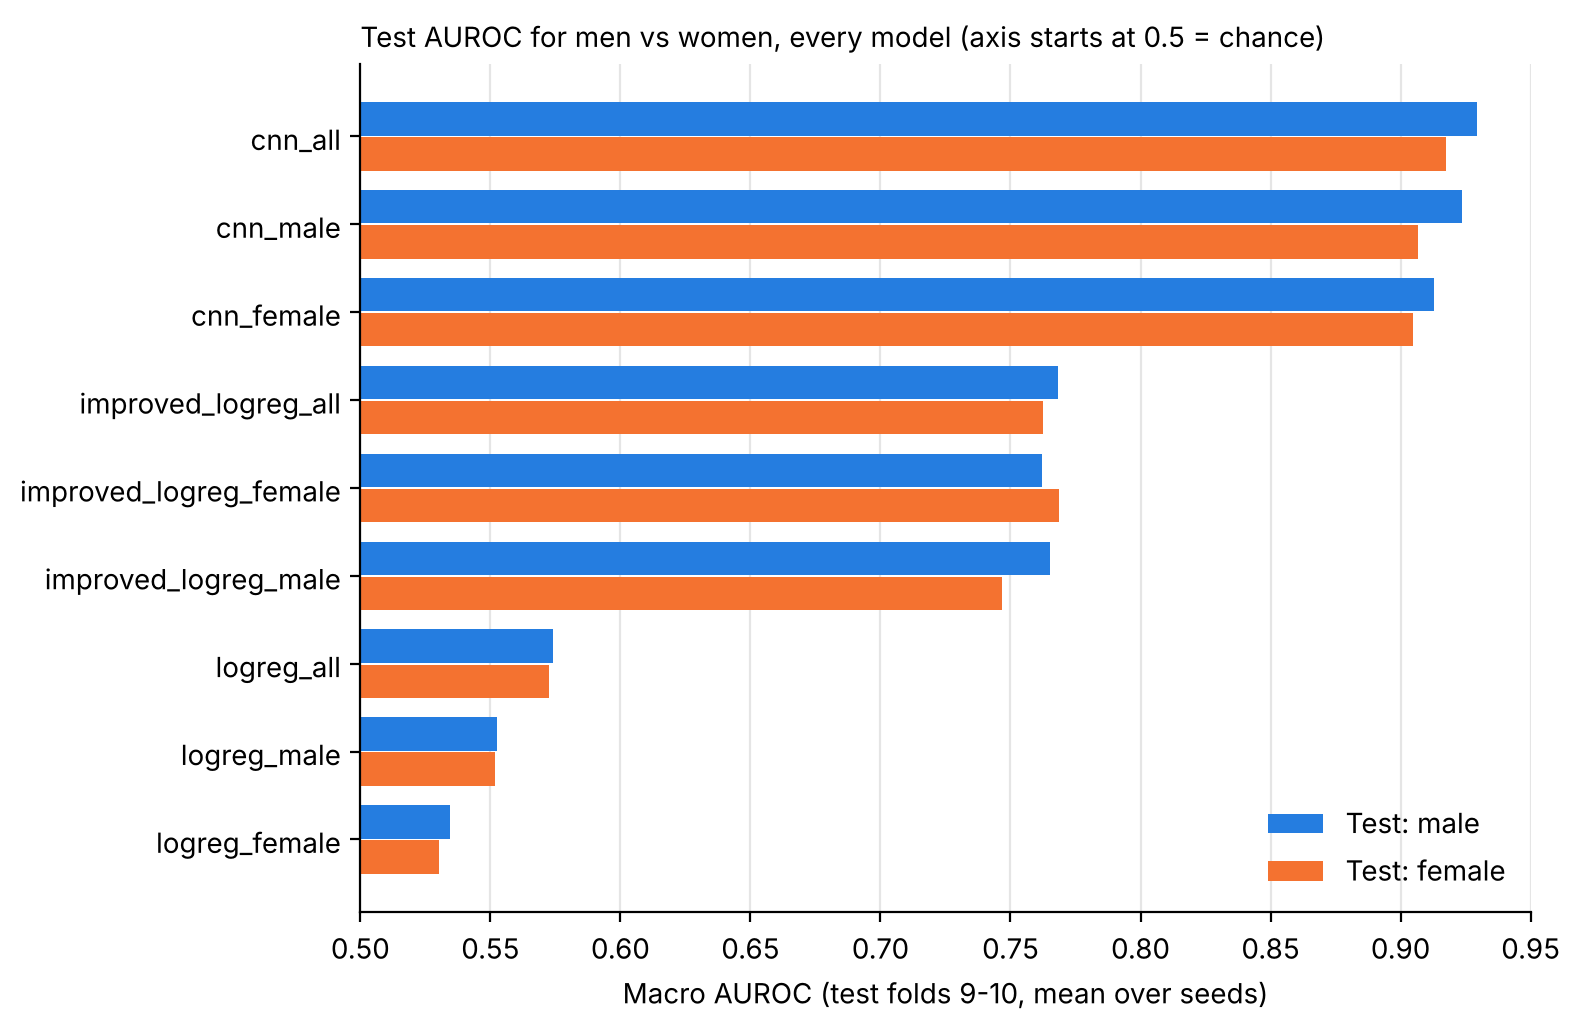

In [3]:
MALE, FEMALE = "#257de0", "#f47230"
order = summary.sort_values("auroc_all_mean").index
fig, ax = plt.subplots(figsize=(8, 0.45 * len(order) + 1.2))
y = range(len(order))
ax.barh([i + 0.2 for i in y], summary.loc[order, "auroc_male_mean"], height=0.38, color=MALE, label="Test: male")
ax.barh([i - 0.2 for i in y], summary.loc[order, "auroc_female_mean"], height=0.38, color=FEMALE, label="Test: female")
ax.set_yticks(list(y), order)
ax.set_xlim(0.5, 0.95)
ax.set_xlabel("Macro AUROC (test folds 9-10, mean over seeds)")
ax.set_title("Test AUROC for men vs women, every model (axis starts at 0.5 = chance)", fontsize=10, loc="left")
ax.legend(loc="lower right", frameon=False)
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
ax.grid(axis="x", color="#e5e5e5"); ax.set_axisbelow(True)
plt.tight_layout()
os.makedirs("../figures/final", exist_ok=True)
plt.savefig("../figures/final/auroc_by_sex_all_models.png", dpi=150, bbox_inches="tight")
plt.show()

## 2. Where the gap lives: per-class AUROC gap (male − female, mean over seeds)

MI is worse for women in every neural model; see the final report for why.

In [4]:
ev.per_class_gap(preds).round(3)

model,cnn_all,cnn_female,cnn_male,improved_logreg_all,improved_logreg_female,improved_logreg_male,logreg_all,logreg_female,logreg_male
cls,,,,,,,,,
NORM,0.007,0.006,0.011,0.007,-0.007,0.024,-0.003,-0.016,0.011
MI,0.021,0.029,0.030,0.012,-0.005,0.031,0.036,0.015,0.025
STTC,0.012,0.008,0.022,0.025,0.001,0.042,-0.009,-0.009,-0.019
CD,0.015,0.003,0.021,-0.001,-0.002,0.003,-0.007,0.004,0.009
HYP,0.007,-0.007,0.001,-0.015,-0.020,-0.008,-0.009,0.027,-0.023


## 3. Missed disease in women at a 0.5 cutoff (seed 0)

Share of true positives in women that the model scores below 0.5. Single seed, so read as rough.

In [5]:
ev.female_miss_rates(preds).round(3)

model,cnn_all,cnn_female,cnn_male,improved_logreg_all,improved_logreg_female,improved_logreg_male,logreg_all,logreg_female,logreg_male
cls,,,,,,,,,
NORM,0.061,0.136,0.199,0.246,0.225,0.364,0.554,0.355,0.755
MI,0.374,0.498,0.287,0.814,0.881,0.696,0.908,0.894,0.797
STTC,0.390,0.223,0.388,0.920,0.869,0.932,0.948,0.863,0.913
CD,0.327,0.373,0.368,0.643,0.670,0.597,0.841,0.865,0.789
HYP,0.545,0.540,0.584,0.708,0.713,0.752,0.941,0.901,0.891


## 4. HuBERT-ECG extension (Check-in 3)

Once `hubert_results/` is in the repo, the HuBERT models appear in every table above automatically. The figures below were produced by `05_hubert_transfer_mean.ipynb`.

HuBERT prediction files found: 0


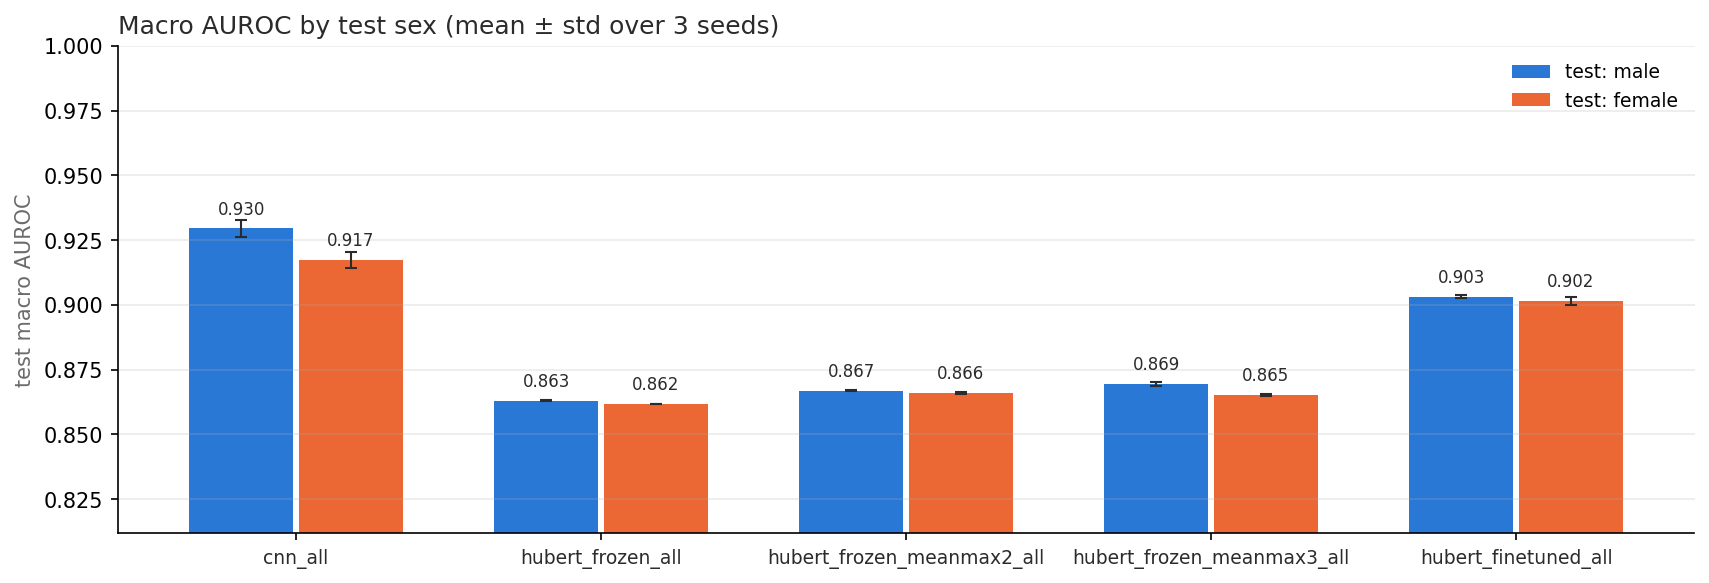

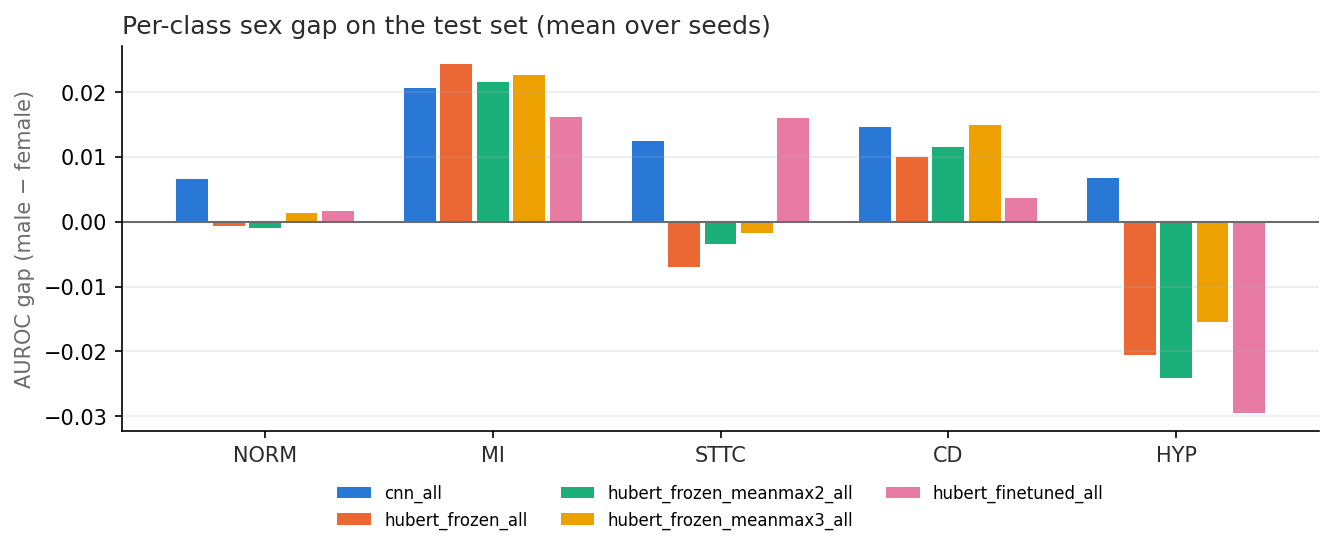

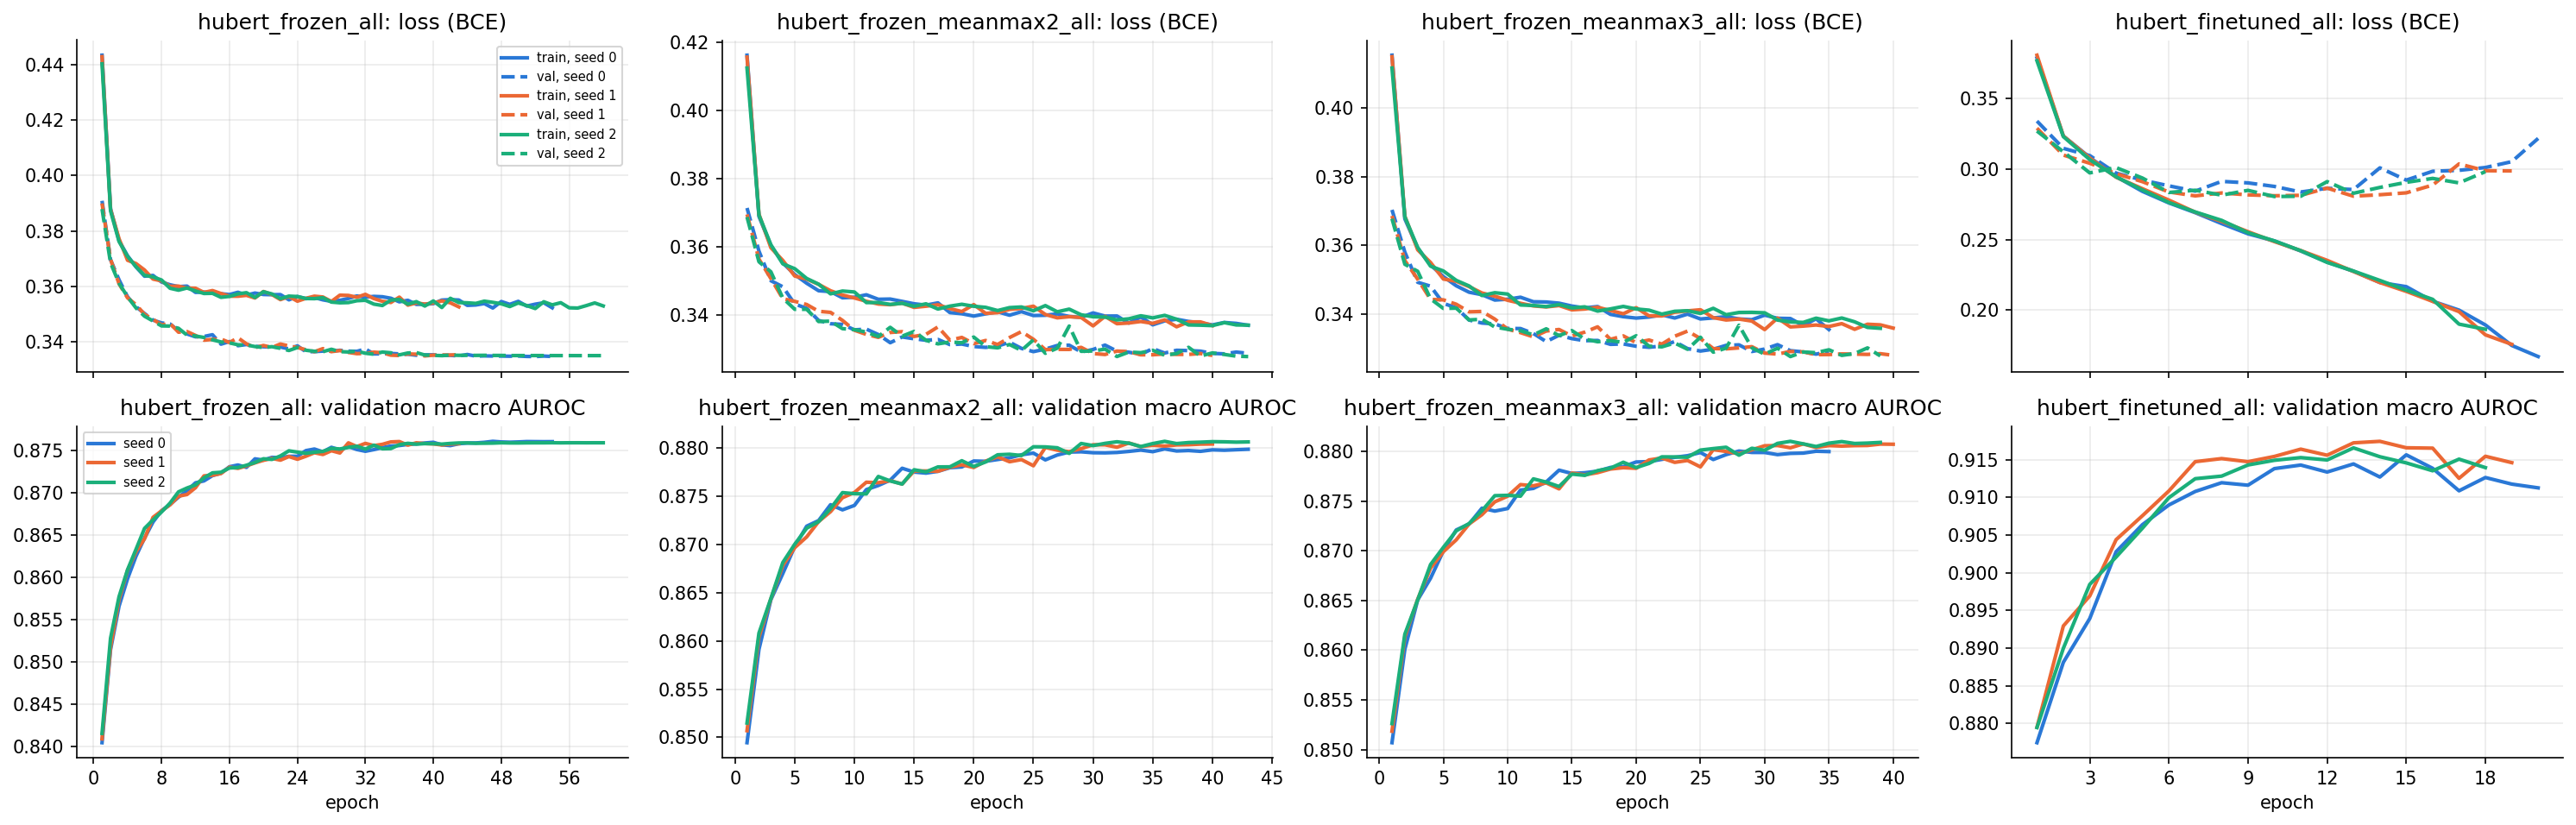

In [6]:
print("HuBERT prediction files found:", sum("hubert" in f for f in files))
for f in ["auroc_by_sex_cnn_vs_hubert", "per_class_gap_cnn_vs_hubert", "hubert_training_curves"]:
    display(Image(f"../figures/hubert_figures/{f}.png", width=750))

In [7]:
# Save the rebuilt tables next to the other results
out = "../results/final"
os.makedirs(out, exist_ok=True)
summary.to_csv(f"{out}/summary_by_model.csv"); runs.to_csv(f"{out}/metrics_by_seed.csv", index=False)
ev.per_class_gap(preds).to_csv(f"{out}/per_class_gap.csv"); ev.female_miss_rates(preds).to_csv(f"{out}/female_miss_rates_seed0.csv")
sorted(os.listdir(out))

['female_miss_rates_seed0.csv',
 'metrics_by_seed.csv',
 'per_class_gap.csv',
 'summary_by_model.csv']